In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("sample - superstore.csv", encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
# Task 1 — Top 10 Products by Sales

product_sales = df.groupby("Product Name")["Sales"].sum()

top_10_products = product_sales.sort_values(
    ascending=False
).head(10)

print(top_10_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [4]:
# Task 2 — Bottom 10 Products by Sales

bottom_10_products = product_sales.sort_values(
    ascending=True
).head(10)

print(bottom_10_products)

Product Name
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac    1.624
Avery 5                                                             5.760
Xerox 20                                                            6.480
Grip Seal Envelopes                                                 7.072
Avery Hi-Liter Pen Style Six-Color Fluorescent Set                  7.700
Avery Hi-Liter Comfort Grip Fluorescent Highlighter, Yellow Ink     7.800
Xerox 1989                                                          7.968
4009 Highlighters                                                   8.040
Stockwell Gold Paper Clips                                          8.096
Newell 308                                                          8.400
Name: Sales, dtype: float64


In [5]:
# Task 3 — Most Profitable Products

product_profit = df.groupby("Product Name")["Profit"].sum()

most_profitable_products = product_profit.sort_values(
    ascending=False
).head(10)

print(most_profitable_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


In [6]:
# Task 4 — Low-Margin Products

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Profit": "sum"
})

product_analysis["Profit Margin"] = (
    product_analysis["Profit"] / product_analysis["Sales"]
) * 100

low_margin_products = product_analysis[
    (product_analysis["Sales"] > product_analysis["Sales"].median()) &
    (product_analysis["Profit Margin"] < product_analysis["Profit Margin"].median())
]

print(low_margin_products.sort_values("Sales", ascending=False))

                                                        Sales        Profit  \
Product Name                                                                  
Cisco TelePresence System EX90 Videoconferencin...  22638.480 -1.811078e+03   
HON 5400 Series Task Chairs for Big and Tall        21870.576  5.684342e-14   
GBC DocuBind TL300 Electric Binding System          19823.479  2.233505e+03   
GBC Ibimaster 500 Manual ProClick Binding System    19024.500  7.609800e+02   
HP Designjet T520 Inkjet Large Format Printer -...  18374.895  4.094977e+03   
...                                                       ...           ...   
KeyTronic E03601U1 - Keyboard - Beige                 324.000  5.832000e+01   
RCA ViSYS 25425RE1 Corded phone                       323.976  3.644730e+01   
Sauder Cornerstone Collection Library                 322.192 -8.116760e+01   
X-Rack File for Hanging Folders                       318.378  6.774000e+01   
Rogers Jumbo File, Granite                          

In [8]:
# Task 5 — Declining Products

monthly_sales = df.groupby(
    ["Product Name", pd.Grouper(key="Order Date", freq="MS")]
)["Sales"].sum().unstack()

sales_change = monthly_sales.diff(axis=1)

declining_products = sales_change[
    (sales_change < 0).sum(axis=1) >= 2
]

print(declining_products.dropna(how="all"))

Order Date                                          2014-01-01  2014-02-01  \
Product Name                                                                 
Accohide Poly Flexible Ring Binders                        NaN         NaN   
Angle-D Binders with Locking Rings, Label Holders          NaN         NaN   
Avery 489                                                  NaN         NaN   
Avery Arch Ring Binders                                    NaN         NaN   
Avery Non-Stick Binders                                    NaN         NaN   
Avery Printable Repositionable Plastic Tabs                NaN         NaN   
Avery Reinforcements for Hole-Punch Pages                  NaN         NaN   
BIC Liqua Brite Liner                                      NaN         NaN   
Belkin Standard 104 key USB Keyboard                       NaN         NaN   
Binding Machine Supplies                                   NaN         NaN   
Bretford CR4500 Series Slim Rectangular Table              NaN  

In [9]:
# Task 6 — Category Performance

category_performance = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)

category_performance["Profit Margin"] = (
    category_performance["Profit"] /
    category_performance["Sales"]
) * 100

print(category_performance)

                       Sales       Profit  Orders  Profit Margin
Category                                                        
Furniture        741999.7953   18451.2728    1764       2.486695
Office Supplies  719047.0320  122490.8008    3742      17.035158
Technology       836154.0330  145454.9481    1544      17.395712


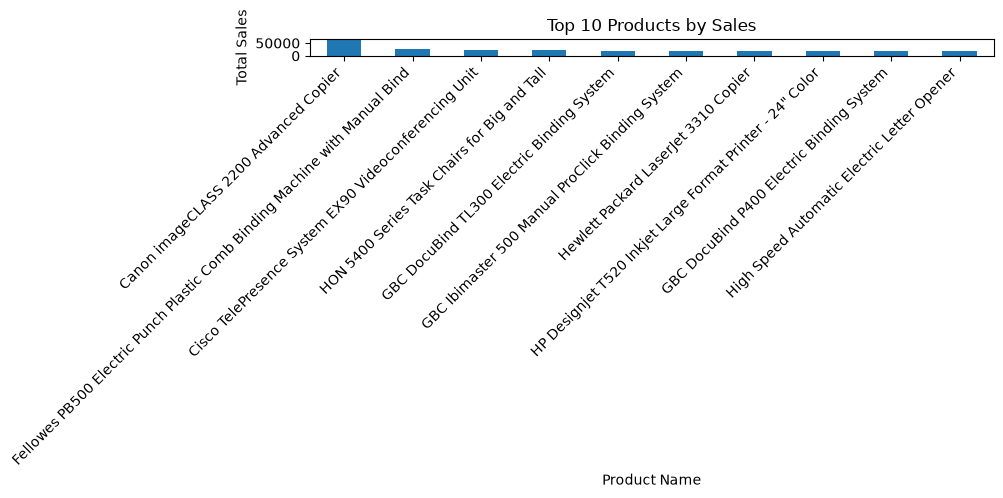

In [10]:
# Task 7.1 — Top 10 Products by Sales

top_10_products.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Products by Sales")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

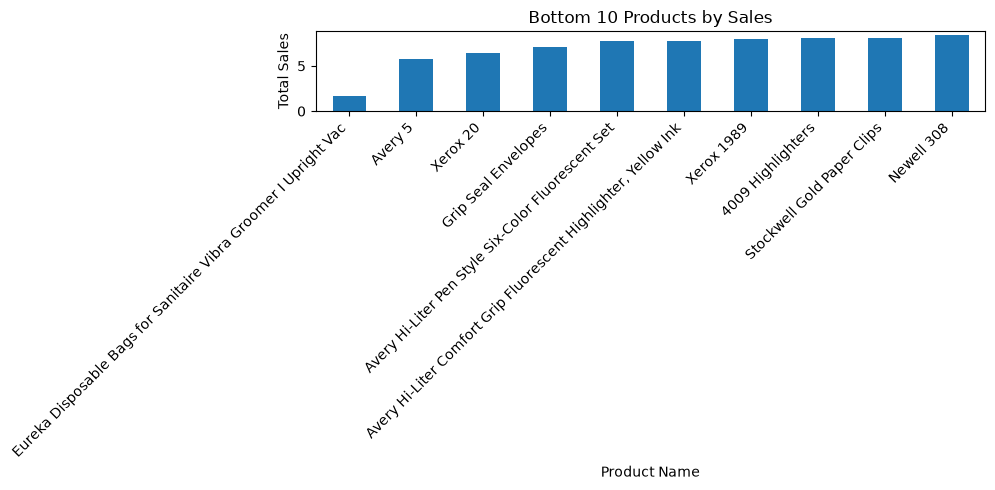

In [11]:
# Task 7.2 — Bottom 10 Products by Sales

bottom_10_products.plot(kind="bar", figsize=(10, 5))

plt.title("Bottom 10 Products by Sales")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

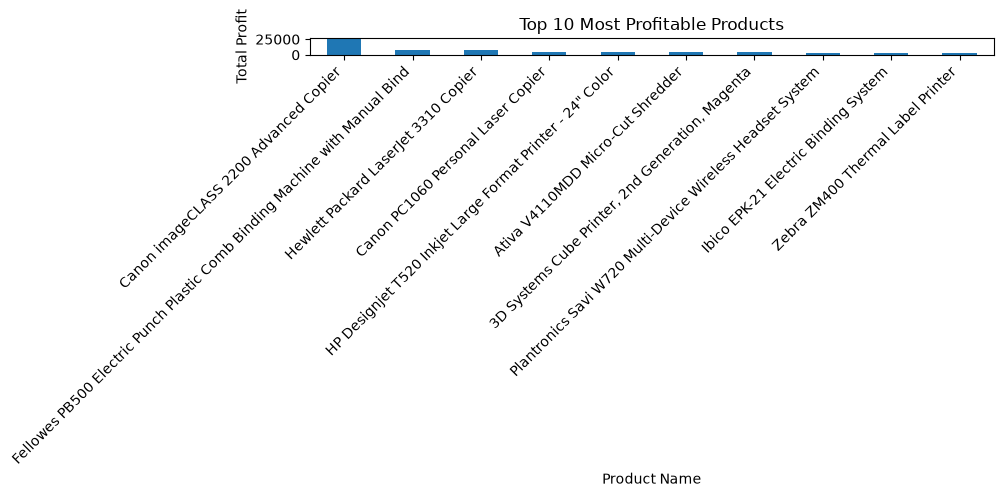

In [12]:
# Task 7.3 — Most Profitable Products

most_profitable_products.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Most Profitable Products")
plt.xlabel("Product Name")
plt.ylabel("Total Profit")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

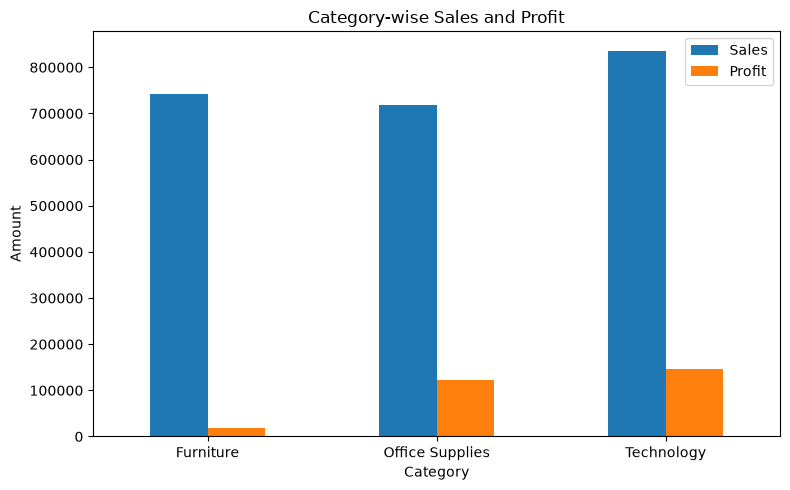

In [13]:
# Task 7.4 — Category Performance

category_performance[["Sales", "Profit"]].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Category-wise Sales and Profit")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# Task 8 — Export Product Performance CSV

product_performance = df.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)

product_performance["Profit Margin"] = (
    product_performance["Profit"] /
    product_performance["Sales"]
) * 100

product_performance.to_csv("Product_Performance.csv")

print("Product_Performance.csv created successfully!")

Product_Performance.csv created successfully!


In [16]:
%pip install python-docx


   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   ---------- ----------------------------- 1.0/4.1 MB 7.1 MB/s eta 0:00:01
   ----------------------- ---------------- 2.4/4.1 MB 6.0 MB/s eta 0:00:01
   ------------------------------------ --- 3.7/4.1 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 4.1/4.1 MB 5.9 MB/s  0:00:00

   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [py


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
# Task 9 — Product Analysis Report

from docx import Document

report = Document()

report.add_heading("Day 27 — Product Analysis Report", 0)

report.add_heading("Objective", level=1)
report.add_paragraph(
    "To identify which products are driving revenue and profit."
)

report.add_heading("1. Top 10 Products by Sales", level=1)
report.add_paragraph(top_10_products.to_string())

report.add_heading("2. Bottom 10 Products by Sales", level=1)
report.add_paragraph(bottom_10_products.to_string())

report.add_heading("3. Most Profitable Products", level=1)
report.add_paragraph(most_profitable_products.to_string())

report.add_heading("4. Low-Margin Products", level=1)
report.add_paragraph(low_margin_products.to_string())

report.add_heading("5. Category Performance", level=1)
report.add_paragraph(category_performance.to_string())

report.add_heading("Conclusion", level=1)
report.add_paragraph(
    "This analysis helps identify top-selling products, "
    "profitable products, low-margin products, and category performance."
)

report.save("Product_Analysis_Report.docx")

print("Product_Analysis_Report.docx created successfully!")

Product_Analysis_Report.docx created successfully!
